In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from pyod.models.auto_encoder import AutoEncoder
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve , auc , accuracy_score
from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score,
                             accuracy_score, precision_score, recall_score, f1_score)
from pyod.models.auto_encoder import AutoEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from pyod.models.auto_encoder import AutoEncoder
from pyod.models.lof import LOF




In [6]:
data_scaled = pd.read_csv("scaled_training_dataset.csv")
data_test_scaled = pd.read_csv("scaled_test_dataset.csv")

In [ ]:
from pyod.models.auto_encoder import AutoEncoder
from pyod.models.lof import LOF
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.metrics import precision_recall_curve
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def calculate_beta_weighted_threshold(y_true, scores, beta=1.0):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    fbeta_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall)
    optimal_idx = np.argmax(fbeta_scores)
    return thresholds[optimal_idx]

def find_best_lof_neighbors(X_train):
    param_grid = {
        'n_neighbors': list(range(5, 31))
    }
    lof = LOF(contamination=0.006)
    grid_search = GridSearchCV(estimator=lof, param_grid=param_grid, scoring='f1', cv=3, n_jobs=-1)
    grid_search.fit(X_train, np.zeros(X_train.shape[0]))
    best_n_neighbors = grid_search.best_params_['n_neighbors']
    return best_n_neighbors

def anomaly_detection_with_lof_autoencoder(data_scaled, data_test_scaled, selected_features, target='is_fraud', beta=1.0):
    X_train = data_scaled[selected_features]
    X_test = data_test_scaled[selected_features]
    y_test = data_test_scaled[target]
    
    lof = LOF(contamination=0.006)
    lof.fit(X_train)
    
    lof_train_scores = lof.decision_function(X_train)
    lof_test_scores = lof.decision_function(X_test)
    
    threshold_lof = np.percentile(lof_train_scores, 80) 
    X_train_filtered = X_train[lof_train_scores >= threshold_lof]
    
    autoencoder = AutoEncoder(lr=0.001, contamination=0.006)
    autoencoder.fit(X_train_filtered)
    
    autoencoder_test_scores = autoencoder.decision_function(X_test)
    
    threshold = calculate_beta_weighted_threshold(y_test, autoencoder_test_scores, beta)
    
    autoencoder_preds = (autoencoder_test_scores < threshold).astype(int)
    
    accuracy = accuracy_score(y_test, autoencoder_preds)
    precision = precision_score(y_test, autoencoder_preds)
    recall = recall_score(y_test, autoencoder_preds)
    f1 = f1_score(y_test, autoencoder_preds)
    roc_auc = roc_auc_score(y_test, autoencoder_preds)
    
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC Score: {roc_auc:.4f}")
    
    cm = confusion_matrix(y_test, autoencoder_preds)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()




Training: 100%|██████████| 10/10 [14:48<00:00, 88.82s/it]


Accuracy: 0.0071
Precision: 0.0020
Recall: 0.5247
F1 Score: 0.0040
ROC AUC Score: 0.2649


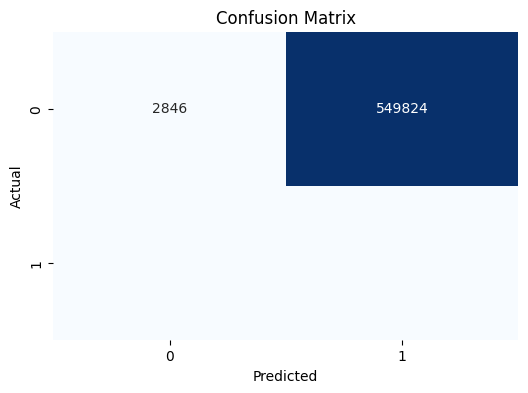

In [4]:
selected_card_features= [
    'category_diversity', 'amt_rolling_mean_7d', 'age_spend_ratio', 'amt',
    'amt_rolling_mean_15d', 'avg_daily_trans'
]
anomaly_detection_with_lof_autoencoder(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features,
    target='is_fraud',
    beta=0.5  
)

Training: 100%|██████████| 10/10 [18:21<00:00, 110.19s/it]


Accuracy: 0.0077
Precision: 0.0020
Recall: 0.5186
F1 Score: 0.0040
ROC AUC Score: 0.2622


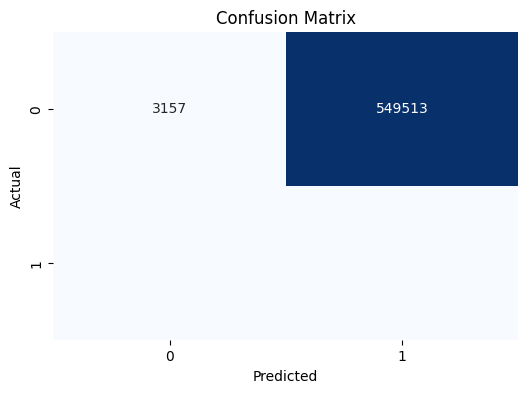

In [5]:
selected_card_features_2= ['category_diversity', 'amt_rolling_mean_7d','age_spend_ratio','amt','amt_rolling_mean_15d','avg_daily_trans','num_trans_per_card','distance_between_transactions','distance_between_cardholder_merchant','amt_std','amt_range']

anomaly_detection_with_lof_autoencoder(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features_2,
    target='is_fraud',
    beta=1 )

Training: 100%|██████████| 10/10 [04:38<00:00, 27.84s/it]
C:\Users\user\AppData\Local\Temp\ipykernel_10288\3736438675.py:11: RuntimeWarning: invalid value encountered in divide
  fbeta_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall)


Accuracy: 0.0039
Precision: 0.0038
Recall: 1.0000
F1 Score: 0.0076
ROC AUC Score: 0.5000


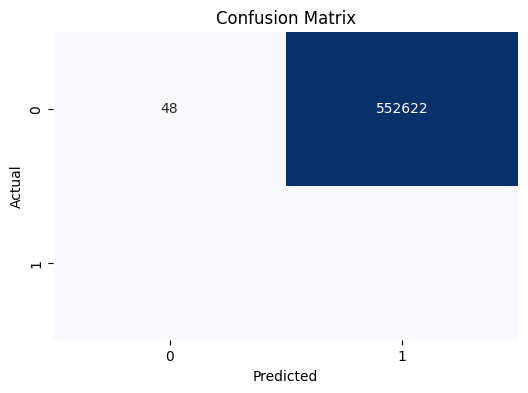

In [6]:
selected_card_features_3= ['category_diversity', 'amt_rolling_mean_7d','age_spend_ratio','amt','amt_rolling_mean_15d','avg_daily_trans','num_trans_per_card','distance_between_transactions','distance_between_cardholder_merchant']
anomaly_detection_with_lof_autoencoder(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features_3,
    target='is_fraud',
    beta=2 
)

In [ ]:
def anomaly_detection_with_lof_autoencoder(data_scaled, data_test_scaled, selected_features, target='is_fraud', beta=1.0):
    X_train = data_scaled[selected_features]
    X_test = data_test_scaled[selected_features]
    y_test = data_test_scaled[target]
    
    lof = LOF(contamination=0.006)
    lof.fit(X_train)
    
    lof_train_scores = lof.decision_function(X_train).reshape(-1, 1)
    lof_test_scores = lof.decision_function(X_test).reshape(-1, 1)
    
    X_train_with_lof = np.hstack((X_train, lof_train_scores))
    X_test_with_lof = np.hstack((X_test, lof_test_scores))
    
    autoencoder = AutoEncoder(lr=0.001, contamination=0.006)
    autoencoder.fit(X_train_with_lof)
    
    autoencoder_test_scores = autoencoder.decision_function(X_test_with_lof)
    
    threshold = calculate_beta_weighted_threshold(y_test, autoencoder_test_scores, beta)
    
    autoencoder_preds = (autoencoder_test_scores < threshold).astype(int)
    
    accuracy = accuracy_score(y_test, autoencoder_preds)
    precision = precision_score(y_test, autoencoder_preds)
    recall = recall_score(y_test, autoencoder_preds)
    f1 = f1_score(y_test, autoencoder_preds)
    roc_auc = roc_auc_score(y_test, autoencoder_preds)
    
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC Score: {roc_auc:.4f}")
    
    cm = confusion_matrix(y_test, autoencoder_preds)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()
    
    comparison_df = data_test_scaled.copy()
    comparison_df['anomaly_score'] = autoencoder_test_scores
    comparison_df['anomaly_pred'] = autoencoder_preds
    
    print(comparison_df[['cc_num', 'is_fraud', 'anomaly_score', 'anomaly_pred']].head(10))  # Display the first 10 rows for comparison

    return comparison_df



Training: 100%|██████████| 10/10 [24:20<00:00, 146.03s/it]
C:\Users\user\AppData\Local\Temp\ipykernel_10288\2040979773.py:12: RuntimeWarning: invalid value encountered in divide
  fbeta_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall)


Accuracy: 0.0285
Precision: 0.0039
Recall: 1.0000
F1 Score: 0.0078
ROC AUC Score: 0.5124


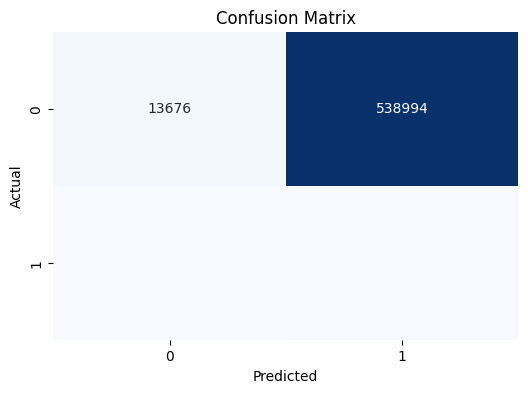

        cc_num  is_fraud  anomaly_score  anomaly_pred
0  60416207185         0       8.522394             1
1  60416207185         0       9.450237             1
2  60416207185         0       9.378434             1
3  60416207185         0       8.444407             1
4  60416207185         0      12.093689             1
5  60416207185         0      16.102062             1
6  60416207185         0      27.481104             1
7  60416207185         0      30.766159             1
8  60416207185         0      30.831118             1
9  60416207185         0      25.096659             1


In [10]:
comparison_df = anomaly_detection_with_lof_autoencoder(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features,
    target='is_fraud',
    beta=0.5  
)


In [7]:
from pyod.models.gmm import GMM
from pyod.models.lof import LOF
from pyod.models.auto_encoder import AutoEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_curve
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def calculate_beta_weighted_threshold(y_true, scores, beta=1.0):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    fbeta_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall)
    optimal_idx = np.argmax(fbeta_scores)
    return thresholds[optimal_idx]

def find_best_lof_neighbors(X_train):
    param_grid = {'n_neighbors': list(range(5, 31))}
    lof = LOF(contamination=0.006)
    grid_search = GridSearchCV(estimator=lof, param_grid=param_grid, scoring='f1', cv=3, n_jobs=-1)
    grid_search.fit(X_train, np.zeros(X_train.shape[0]))  
    return grid_search.best_params_['n_neighbors']

def gmm_anomaly_detection(X_train, X_test, contamination=0.006, prob_threshold=0.1):
    X_train = X_train.values if hasattr(X_train, 'values') else X_train
    X_test = X_test.values if hasattr(X_test, 'values') else X_test
    
    gmm = GMM(contamination=contamination)
    gmm.fit(X_train)
    
    train_probs = gmm.predict_proba(X_train)
    test_probs = gmm.predict_proba(X_test)
    
    train_max_probs = np.max(train_probs, axis=1)
    test_max_probs = np.max(test_probs, axis=1)
    
    train_anomalies = (train_max_probs < prob_threshold).astype(int).reshape(-1, 1)
    test_anomalies = (test_max_probs < prob_threshold).astype(int).reshape(-1, 1)
    
    return train_anomalies, test_anomalies


def lof_anomaly_detection(X_train, X_test, best_n_neighbors, lof_threshold=2.0):
    lof = LOF(n_neighbors=best_n_neighbors, contamination=0.006)
    lof.fit(X_train)
    
    lof_train_scores = lof.decision_function(X_train)
    lof_test_scores = lof.decision_function(X_test)
    
    train_anomalies = (lof_train_scores > lof_threshold).astype(int).reshape(-1, 1)
    test_anomalies = (lof_test_scores > lof_threshold).astype(int).reshape(-1, 1)
    
    return train_anomalies, test_anomalies

def anomaly_detection_gmm_lof_autoencoder(data_scaled, data_test_scaled, selected_features, target='is_fraud', beta=1.0):
    X_train = data_scaled[selected_features]
    X_test = data_test_scaled[selected_features]
    y_test = data_test_scaled[target]
    
    gmm_train_anomalies, gmm_test_anomalies = gmm_anomaly_detection(X_train, X_test)
    
    best_n_neighbors = find_best_lof_neighbors(X_train)
    lof_train_anomalies, lof_test_anomalies = lof_anomaly_detection(X_train, X_test, best_n_neighbors)
    
    X_train_combined = np.hstack((X_train, gmm_train_anomalies, lof_train_anomalies))
    X_test_combined = np.hstack((X_test, gmm_test_anomalies, lof_test_anomalies))
    
    autoencoder = AutoEncoder(lr=0.001, contamination=0.006)
    autoencoder.fit(X_train_combined)
    
    autoencoder_test_scores = autoencoder.decision_function(X_test_combined)
    
    threshold = calculate_beta_weighted_threshold(y_test, autoencoder_test_scores, beta)
    
    final_preds = (autoencoder_test_scores < threshold).astype(int)  
    
    accuracy = accuracy_score(y_test, final_preds)
    precision = precision_score(y_test, final_preds)
    recall = recall_score(y_test, final_preds)
    f1 = f1_score(y_test, final_preds)
    roc_auc = roc_auc_score(y_test, final_preds)
    
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC Score: {roc_auc:.4f}")
    
    cm = confusion_matrix(y_test, final_preds)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()



In [8]:
selected_card_features = [
    'category_diversity', 'amt_rolling_mean_7d', 'age_spend_ratio', 'amt',
    'amt_rolling_mean_15d', 'avg_daily_trans', 'num_trans_per_card',
    'distance_between_transactions', 'distance_between_cardholder_merchant'
]

anomaly_detection_gmm_lof_autoencoder(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features,
    target='is_fraud',
    beta=0.5  
)


KeyboardInterrupt: 

In [ ]:
# Example selected card features
selected_card_features = [
    'category_diversity', 'amt_rolling_mean_7d', 'age_spend_ratio', 'amt',
    'amt_rolling_mean_15d', 'avg_daily_trans', 'num_trans_per_card',
    'distance_between_transactions', 'distance_between_cardholder_merchant'
]

# Example usage with a fixed beta value (e.g., beta = 0.5) to give more weight to precision
anomaly_detection_gmm_lof_autoencoder(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features,
    target='is_fraud',
    beta=2 # Fixed beta value to give more weight to precision
)


In [ ]:
def anomaly_detection_gmm_lof_autoencoder(data_scaled, data_test_scaled, selected_features, target='is_fraud', beta=1.0):
    X_train = data_scaled[selected_features]
    X_test = data_test_scaled[selected_features]
    y_test = data_test_scaled[target]
    cc_num_test = data_test_scaled['cc_num']  # Assuming 'cc_num' is in your data_test_scaled

    # Step 1: GMM Anomaly Detection with custom probability condition
    gmm_train_anomalies, gmm_test_anomalies = gmm_anomaly_detection(X_train, X_test)
    
    # Step 2: LOF Anomaly Detection with logical condition
    best_n_neighbors = find_best_lof_neighbors(X_train)
    lof_train_anomalies, lof_test_anomalies = lof_anomaly_detection(X_train, X_test, best_n_neighbors)
    
    # Combine GMM, LOF anomalies with the original features
    X_train_combined = np.hstack((X_train, gmm_train_anomalies, lof_train_anomalies))
    X_test_combined = np.hstack((X_test, gmm_test_anomalies, lof_test_anomalies))
    
    # Step 3: AutoEncoder on Combined Features
    autoencoder = AutoEncoder(lr=0.001, contamination=0.006)
    autoencoder.fit(X_train_combined)
    
    autoencoder_test_scores = autoencoder.decision_function(X_test_combined)
    
    # Calculate the beta-weighted threshold
    threshold = calculate_beta_weighted_threshold(y_test, autoencoder_test_scores, beta)
    
    # Get final anomaly predictions
    final_preds = (autoencoder_test_scores < threshold).astype(int)  # 0 for normal, 1 for anomaly
    
    # Create a DataFrame for comparison
    results_df = data_test_scaled.copy()
    results_df['mse'] = autoencoder_test_scores
    results_df['predicted_is_fraud'] = final_preds
    
    # Set cc_num as index
    results_df.set_index('cc_num', inplace=True)
    
    # Sort by MSE in descending order
    sorted_results_df = results_df.sort_values(by='mse', ascending=False)
    
    # Print the evaluation metrics
    accuracy = accuracy_score(y_test, final_preds)
    precision = precision_score(y_test, final_preds)
    recall = recall_score(y_test, final_preds)
    f1 = f1_score(y_test, final_preds)
    roc_auc = roc_auc_score(y_test, final_preds)
    
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC Score: {roc_auc:.4f}")
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, final_preds)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

    return sorted_results_df[['mse', 'predicted_is_fraud', 'is_fraud']]

# Example usage with a fixed beta value (e.g., beta = 0.5) to give more weight to precision
sorted_results_df = anomaly_detection_gmm_lof_autoencoder(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features,
    target='is_fraud',
    beta=0.5  # Fixed beta value to give more weight to precision
)

# Display the sorted DataFrame
print(sorted_results_df)
